# SiteWise · volumen 2 con suelo industrial
## Objetivo y estado de la entrega · 14/11/2026
Ampliamos la v0.1 con **recurso solar, contexto hídrico, proximidad logística y suelo industrial cartografiado**. Se han incorporado los dos GeoPackage del IGN aportados por Elena. El cuaderno contiene las limpiezas, cruces, controles y exportaciones; utiliza copias incluidas y conserva los datos anteriores.

**Regla de la aplicación:** un dato desconocido no supera un requisito mínimo. Estrés hídrico no certifica caudal industrial; área industrial no certifica parcelas libres; proximidad a una autovía no certifica acceso ni tiempo de viaje. La superficie del catálogo delimita las principales áreas industriales de referencia 2020, no un inventario completo de cada actividad o parcela.


**Resultado comprobado:** 25 indicadores en el esquema municipal (16 anteriores y 9 de esta ampliación). El suelo industrial cartografiado intersecta **3.699 municipios**; otros **4.433** no contienen polígonos del catálogo. No son hectáreas de suelo libre. Las 18 celdas de código se han ejecutado, con cinco gráficos guardados.

## 1. Preparar el entorno
Desde la raíz del proyecto: `python -m pip install -r requirements.txt`. En VS Code hay que seleccionar ese mismo entorno como kernel. Las dependencias fijadas contemplan Python 3.14 en Windows.

El cuaderno localiza la raíz desde `notebooks/` o desde el proyecto. Si solo se ha recibido esta ampliación, las tablas base necesarias de v0.1 también están incluidas. No se necesitan los originales voluminosos para repetir los cálculos.

In [1]:
from pathlib import Path
import json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box, Point
from pyproj import Transformer, Geod
import rasterio
from rasterio.windows import from_bounds, Window
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/processed/sitewise_v01/municipios.csv').exists())
BASE = ROOT / 'data/processed/sitewise_v01'
RAW = ROOT / 'data/raw/sitewise_v02'
OUT = ROOT / 'data/processed/sitewise_v02'
QA = ROOT / 'docs/data/sitewise_v02'
OUT.mkdir(parents=True, exist_ok=True)
QA.mkdir(parents=True, exist_ok=True)
COBERTURA_MINIMA = 0.95  # decisión metodológica visible; no es un umbral oficial
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.grid': False, 'savefig.dpi': 140})
def figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(QA / nombre, bbox_inches='tight')
    display(fig)
    plt.close(fig)
def csv(df, nombre, carpeta=OUT):
    df.to_csv(carpeta / nombre, index=False, encoding='utf-8-sig')
print('Raíz:', ROOT.name, '| Python:', platform.python_version(), '| pandas:', pd.__version__)

Raíz: Final_sidewise | Python: 3.14.6 | pandas: 2.3.3


## 2. Fuentes y trazabilidad

| Bloque | Fuente | Qué utilizamos | Fecha y escala |
|---|---|---|---|
| Solar | Comisión Europea, JRC/PVGIS 5.3, CC BY 4.0 | Irradiación global horizontal SARAH3, kWh/m²/año | Media 2005–2023; celdas 0,05° |
| Agua | WRI, Aqueduct 4.0, CC BY 4.0 | Estrés y agotamiento hídrico; geometrías de subcuenca intersectadas con unidades administrativas/acuíferos | Baseline objetivo 2019; publicación 2023; modelo histórico 1979–2019 |
| Ferrocarril | ADIF, PISERVI | Instalaciones catalogadas explícitamente como TTM; subconjunto intermodal | Copia consultada 13/11/2026; fecha de actualización individual no publicada |
| Carreteras | Ministerio de Transportes, HERMES, capa nacional 0_CARRETERAS/19 | Ejes con tipo Autopista/Autovía | Consulta 13/11/2026; fechas de validez de la fuente conservadas |
| Suelo industrial | IGN/CNIG, caso de uso de SIOSE | Delimitación industrial 2020, dos GeoPackage | Aportados por Elena el 14/11/2026; capa MSI |

Enlaces, consultas y SHA-256 se guardan en `fuentes_ampliacion.json`. Las geometrías de Aqueduct **no son una tabla agregada por comunidad autónoma**: el valor hidrológico procede de subcuencas. `name_1` solo identifica uno de los recortes de la geometría; no se copia una media autonómica a los municipios.

Referencias: [PVGIS 5.3](https://data.jrc.ec.europa.eu/dataset/eef67979-e4a9-46f1-80f4-16fe2a266634), [Aqueduct, datos](https://www.wri.org/data/aqueduct-global-maps-40-data), [metodología WRI](https://doi.org/10.46830/writn.23.00061), [PISERVI](https://piservi.adif.es/piservi/portal), [HERMES nacional](https://mapas.fomento.gob.es/arcgis2/rest/services/Hermes/0_CARRETERAS/MapServer/19), [suelo industrial](https://centrodedescargas.cnig.es/CentroDescargas/mapa-suelo-industrial).

In [2]:
fuentes = json.loads((RAW / 'fuentes_ampliacion.json').read_text(encoding='utf-8'))
for nombre, esperado in fuentes['archivos_incluidos_sha256'].items():
    assert hashlib.sha256((RAW / nombre).read_bytes()).hexdigest() == esperado, nombre
display(pd.DataFrame(fuentes['fuentes'])[['id', 'organismo', 'periodo', 'estado']])
print('Integridad de las copias incluidas: correcta')

,id,organismo,periodo,estado
0,pvgis53,Comisión Europea / JRC,2005–2023,descargada
1,aqueduct4,World Resources Institute (WRI),Baseline objetivo2019; modelo1979–2019; public...,descargada
2,adif,ADIF / PISERVI,consulta2026-11-13,descargada
3,hermes,Ministerio de Transportes / HERMES,consulta2026-11-13,descargada
4,cnig_industrial,IGN / CNIG,2020,recibida_y_verificada


Integridad de las copias incluidas: correcta


### 2.1. Cómo se prepararon las copias espaciales ligeras
El TIFF original continental pesa 51 MB y el ZIP mundial de Aqueduct, 262 MB. Se incluyen sus recortes espaciales para España, sin redondear valores ni simplificar geometrías. El código siguiente reproduce esa selección si se dispone de los originales descargados de las URL del manifiesto. **No hace falta activarlo** para ejecutar el resto.

Esta selección reduce espacio y no sustituye la limpieza: los nulos, las coberturas, los solapes y la agregación se resuelven después. El diccionario WRI y el catálogo original de PVGIS también están incluidos. Las copias ADIF y HERMES conservan las respuestas completas de sus consultas.

Los dos GeoPackage industriales originales se incluyen completos en `data/raw/sitewise_v02/suelo_industrial/`. Sus CRS son diferentes: ETRS89/EPSG:4258 para Península-Baleares-Ceuta-Melilla y REGCAN95/EPSG:4080 para Canarias. Se reproyectan antes de calcular áreas. No se modifican los archivos recibidos.

In [3]:
def preparar_recortes(carpeta_originales):
    import zipfile, tempfile
    carpeta_originales = Path(carpeta_originales)
    originales = {
        'solar_sarah3_2005_2023.tif': fuentes['originales_sha256']['solar_sarah3_2005_2023.tif'],
        'aqueduct4_global.zip': fuentes['originales_sha256']['aqueduct4_global.zip']}
    for nombre, esperado in originales.items():
        assert hashlib.sha256((carpeta_originales / nombre).read_bytes()).hexdigest() == esperado
    with rasterio.open(carpeta_originales / 'solar_sarah3_2005_2023.tif') as src:
        ventana = from_bounds(-18.3, 27.5, 4.4, 43.9, src.transform).round_offsets().round_lengths()
        valores = src.read(window=ventana)
        perfil = src.profile.copy()
        perfil.update(width=valores.shape[2], height=valores.shape[1],
                      transform=src.window_transform(ventana), compress='deflate')
        with rasterio.open(RAW / 'pvgis53_sarah3_ghi_espana.tif', 'w', **perfil) as dst:
            dst.write(valores)
    with tempfile.TemporaryDirectory() as tmp:
        with zipfile.ZipFile(carpeta_originales / 'aqueduct4_global.zip') as z:
            for miembro in z.namelist():
                if '/GDB/' in miembro:
                    z.extract(miembro, tmp)
        gdb = next(Path(tmp).rglob('*.gdb'))
        columnas = ['string_id', 'name_0', 'name_1', 'pfaf_id', 'bws_raw', 'bws_score',
                    'bws_cat', 'bws_label', 'bwd_raw', 'bwd_score', 'bwd_cat', 'bwd_label',
                    'iav_raw', 'iav_score', 'sev_raw', 'sev_score']
        agua = gpd.read_file(gdb, layer='baseline_annual', bbox=(-19, 27, 5, 44), columns=columnas)
        agua.loc[agua.name_0.eq('Spain')].to_file(
            RAW / 'aqueduct4_espana.gpkg', layer='baseline_annual', driver='GPKG')

RECONSTRUIR_RECORTES = False
if RECONSTRUIR_RECORTES:
    preparar_recortes(ROOT / 'data/cache/originales_v02')
else:
    print('Se utilizan las copias espaciales incluidas; no se requiere conexión.')

Se utilizan las copias espaciales incluidas; no se requiere conexión.


## 3. Revisar la base municipal
Mantenemos los 8.132 códigos INE de cinco caracteres de la v0.1. Las geometrías GISCO 2024 son generalizadas, por lo que las áreas calculadas y los cruces tienen precisión de análisis territorial, no catastral. No son adecuadas para decidir si una parcela concreta está afectada.

Para ponderar superficies usamos EPSG:6933, una proyección equivalente. El denominador es el área de la **misma geometría** utilizada en cada intersección; no mezclamos el área publicada con otra frontera. Los puntos interiores de v0.1 sirven solo para las distancias logísticas y no representan necesariamente el núcleo urbano.

In [4]:
municipios = pd.read_csv(BASE / 'municipios.csv', dtype={'cod_ine':str, 'cod_provincia':str})
geo = gpd.read_file(BASE / 'municipios.geojson').sort_values('cod_ine').reset_index(drop=True)
geo['geometry'] = shapely.make_valid(geo.geometry.values)
assert len(geo) == 8132 and geo.cod_ine.is_unique
assert geo.cod_ine.str.fullmatch(r'\d{5}').all()
assert set(geo.cod_ine) == set(municipios.cod_ine)
assert geo.geometry.is_valid.all() and not geo.geometry.is_empty.any()
geo_area = geo.to_crs(6933)
area_municipal = pd.Series(geo_area.area.values, index=geo.cod_ine)
proyectar_area = Transformer.from_crs(4326, 6933, always_xy=True).transform
display(municipios[['cod_ine', 'nombre', 'provincia']].head())

,cod_ine,nombre,provincia
0,01051,Agurain/Salvatierra,Araba/Álava
1,01001,Alegría-Dulantzi,Araba/Álava
2,01002,Amurrio,Araba/Álava
3,01049,Añana,Araba/Álava
4,01003,Aramaio,Araba/Álava


## 4. Recurso solar: media ponderada por superficie
PVGIS publica irradiación global horizontal, no horas de sol ni producción garantizada de una planta. Elegimos GHI para poder comparar el recurso antes de definir orientación, potencia, pérdidas y tecnología.

Intersectamos cada municipio con las celdas del TIFF. Cada celda aporta su valor multiplicado por la superficie que realmente comparte con el municipio. Este método también funciona en municipios menores que una celda: no inventa una precisión superior a la rejilla. Excluimos `-9999`, nunca lo tratamos como irradiación cero. Publicamos la media si la cobertura válida alcanza el 95%; guardamos la cobertura y el número de celdas utilizadas.

In [5]:
solar_filas = []
with rasterio.open(RAW / 'pvgis53_sarah3_ghi_espana.tif') as src:
    assert src.crs.to_epsg() == 4326
    for cod, poligono, area_total in zip(geo.cod_ine, geo.geometry, geo_area.area):
        w = from_bounds(*poligono.bounds, src.transform)
        c0, f0 = max(0, int(np.floor(w.col_off))), max(0, int(np.floor(w.row_off)))
        c1 = min(src.width, int(np.ceil(w.col_off + w.width)))
        f1 = min(src.height, int(np.ceil(w.row_off + w.height)))
        numerador = area_valida = 0.0
        n_celdas = 0
        if c1 > c0 and f1 > f0:
            valores = src.read(1, window=Window(c0, f0, c1-c0, f1-f0))
            for fila, columna in np.argwhere(np.isfinite(valores) & (valores != src.nodata)):
                x0, y0 = src.transform * (c0+int(columna), f0+int(fila))
                x1, y1 = src.transform * (c0+int(columna)+1, f0+int(fila)+1)
                interseccion = poligono.intersection(box(x0, y1, x1, y0))
                if interseccion.is_empty:
                    continue
                area = shapely.transform(interseccion, proyectar_area, interleaved=False).area
                if area > 0:
                    numerador += float(valores[fila, columna]) * area
                    area_valida += area
                    n_celdas += 1
        cobertura = area_valida / area_total
        assert cobertura <= 1.0001, (cod, cobertura)
        media = numerador/area_valida if area_valida and cobertura >= COBERTURA_MINIMA else np.nan
        solar_filas.append((cod, media, 100*min(cobertura, 1), n_celdas))
solar = pd.DataFrame(solar_filas, columns=['cod_ine', 'irradiacion_ghi_kwh_m2_anio',
    'solar_cobertura_pct', 'solar_celdas'])
assert solar.irradiacion_ghi_kwh_m2_anio.dropna().between(500, 3000).all()
csv(solar, 'solar_municipal.csv')
display(solar.describe().round(2))

,irradiacion_ghi_kwh_m2_anio,solar_cobertura_pct,solar_celdas
count,8132.00,8132.00,8132.00
mean,1670.84,100.00,7.95
std,154.04,0.00,6.70
min,1055.35,99.99,1.00
25%,1618.36,100.00,4.00
50%,1698.01,100.00,6.00
75%,1757.67,100.00,9.00
max,2126.68,100.00,115.00


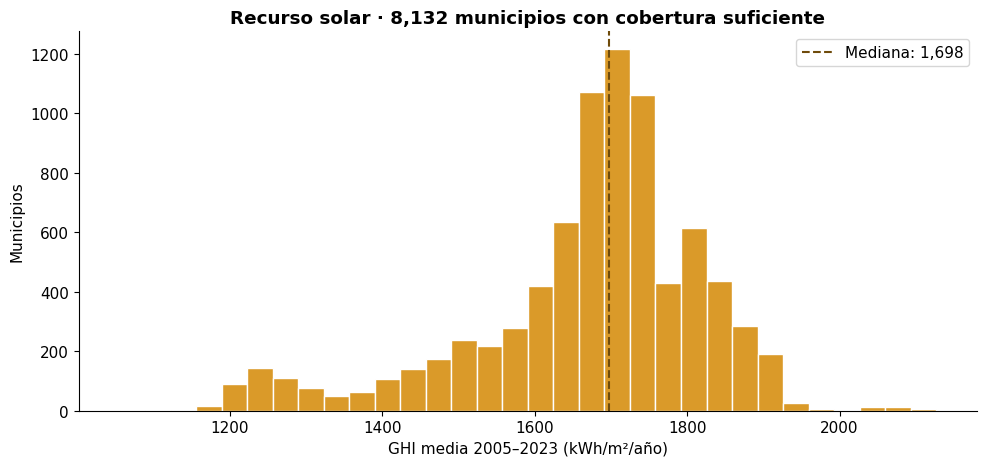

La mediana municipal es **1,698 kWh/m²/año**. Cada municipio cuenta una vez; no es una media de España ponderada por superficie. No equivale a rendimiento fotovoltaico ni a una predicción para 2026.

In [6]:
fig, ax = plt.subplots()
s = solar.irradiacion_ghi_kwh_m2_anio.dropna()
ax.hist(s, bins=32, color='#da9a29', edgecolor='white')
ax.axvline(s.median(), color='#6f4b0b', linestyle='--', label=f'Mediana: {s.median():,.0f}')
ax.set(title=f'Recurso solar · {len(s):,} municipios con cobertura suficiente',
       xlabel='GHI media 2005–2023 (kWh/m²/año)', ylabel='Municipios')
ax.legend()
figura(fig, '01_recurso_solar.png')
display(Markdown(f'La mediana municipal es **{s.median():,.0f} kWh/m²/año**. '
    'Cada municipio cuenta una vez; no es una media de España ponderada por superficie. '
    'No equivale a rendimiento fotovoltaico ni a una predicción para 2026.'))

## 5. Agua: contexto de estrés y agotamiento hídrico
Aqueduct es una fuente modelizada de WRI, no un inventario de concesiones industriales. El estrés (`bws_raw`) compara extracciones y recursos renovables disponibles; el agotamiento (`bwd_raw`) compara consumo neto y disponibilidad. Conservamos ambos como porcentaje, incluidos valores de estrés superiores al 100%: no se recortan.

La baseline tiene año objetivo **2019**, estimado a partir del modelo histórico 1979–2019; publicación 2023. No describe la sequía del mes actual. Excluimos valores centinela negativos y guardamos las etiquetas originales. No usamos el índice compuesto sectorial de WRI para fabricar una puntuación SiteWise.

Intersectamos geometrías hidrológicas con municipios y ponderamos por área válida. Guardamos cada intersección para auditar qué subcuencas contribuyen a cada municipio. La cuota territorial con estrés ≥40% es descriptiva; **no es un umbral eliminatorio aprobado por el equipo**.

In [7]:
agua = gpd.read_file(RAW / 'aqueduct4_espana.gpkg', layer='baseline_annual')
assert agua.string_id.is_unique and agua.name_0.eq('Spain').all()
agua['geometry'] = shapely.make_valid(agua.geometry.values)
for col in ['bws_raw', 'bwd_raw']:
    agua[col] = pd.to_numeric(agua[col], errors='coerce').where(lambda s: s.ge(0))
inter = gpd.overlay(geo_area[['cod_ine','geometry']],
    agua[['string_id','pfaf_id','bws_raw','bwd_raw','geometry']].to_crs(6933),
    how='intersection', keep_geom_type=True, make_valid=True)
inter['area_interseccion_m2'] = inter.area
inter = inter[inter.area_interseccion_m2.gt(0)].copy()
csv(inter.drop(columns='geometry'), 'agua_intersecciones.csv')
agua_filas = []
for cod, grupo in inter.groupby('cod_ine', sort=False):
    fila = {'cod_ine':cod, 'agua_subcuencas':grupo.pfaf_id.nunique()}
    for col, nombre in [('bws_raw','estres_hidrico'), ('bwd_raw','agotamiento_hidrico')]:
        validos = grupo[col].notna()
        area_valida = grupo.loc[validos, 'area_interseccion_m2'].sum()
        cobertura = area_valida / area_municipal[cod]
        assert cobertura <= 1.0001, (cod, cobertura)
        fila[nombre+'_cobertura_pct'] = 100*min(cobertura, 1)
        fila[nombre+'_pct'] = (100*np.average(grupo.loc[validos,col],
            weights=grupo.loc[validos,'area_interseccion_m2'])
            if area_valida and cobertura >= COBERTURA_MINIMA else np.nan)
    validos = grupo.bws_raw.notna()
    area_valida = grupo.loc[validos,'area_interseccion_m2'].sum()
    fila['superficie_estres_ge40_pct'] = (100*grupo.loc[validos & grupo.bws_raw.ge(.4),
        'area_interseccion_m2'].sum()/area_valida
        if area_valida and fila['estres_hidrico_cobertura_pct'] >= 100*COBERTURA_MINIMA else np.nan)
    agua_filas.append(fila)
hidrica = geo[['cod_ine']].merge(pd.DataFrame(agua_filas), on='cod_ine', how='left', validate='one_to_one')
for col in ['estres_hidrico_cobertura_pct', 'agotamiento_hidrico_cobertura_pct']:
    hidrica[col] = hidrica[col].fillna(0)
assert hidrica.superficie_estres_ge40_pct.dropna().between(0,100.00001).all()
csv(hidrica, 'agua_municipal.csv')
display(hidrica.drop(columns='cod_ine').describe().round(2))

,agua_subcuencas,estres_hidrico_cobertura_pct,estres_hidrico_pct,agotamiento_hidrico_cobertura_pct,agotamiento_hidrico_pct,superficie_estres_ge40_pct
count,8132.00,8132.00,8108.00,8132.00,8108.00,8108.00
mean,1.26,99.90,138.50,99.90,64.14,69.15
std,0.50,0.95,187.92,0.95,84.17,45.31
min,1.00,49.80,0.70,49.80,0.22,0.00
25%,1.00,100.00,37.44,100.00,17.47,0.00
50%,1.00,100.00,64.23,100.00,34.45,100.00
75%,1.00,100.00,148.92,100.00,66.24,100.00
max,5.00,100.00,962.26,100.00,516.44,100.00


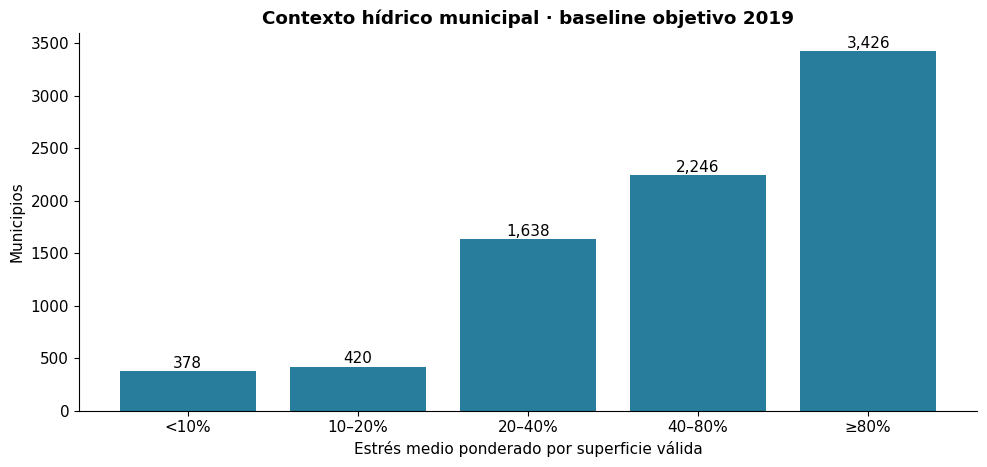

**8,108 municipios** alcanzan la cobertura mínima. Los restantes conservan el dato ausente. Las bandas resumen una media municipal derivada: no son certificaciones de abastecimiento ni las categorías originales de cada subcuenca.

In [8]:
fig, ax = plt.subplots()
rangos = pd.cut(hidrica.estres_hidrico_pct, [0,10,20,40,80,np.inf],
    labels=['<10%', '10–20%', '20–40%', '40–80%', '≥80%'], right=False, include_lowest=True)
cuentas = rangos.value_counts(sort=False).rename_axis('rango').reset_index(name='municipios')
ax.bar(cuentas.rango.astype(str), cuentas.municipios, color='#277d9b')
for i, v in enumerate(cuentas.municipios): ax.text(i, v+30, f'{v:,}', ha='center')
ax.set(title='Contexto hídrico municipal · baseline objetivo 2019',
       xlabel='Estrés medio ponderado por superficie válida', ylabel='Municipios')
figura(fig, '02_contexto_hidrico.png')
display(Markdown(f'**{hidrica.estres_hidrico_pct.notna().sum():,} municipios** alcanzan la cobertura mínima. '
    'Los restantes conservan el dato ausente. Las bandas resumen una media municipal derivada: '
    'no son certificaciones de abastecimiento ni las categorías originales de cada subcuenca.'))

## 6. Logística: limpiar instalaciones y separar territorios
PISERVI contiene estaciones de viajeros, talleres, cargaderos y puertos. Para medir proximidad a terminales de mercancías seleccionamos **solo los tipos que contienen TTM**, no cualquier estación. Para intermodalidad exigimos además `MERCANCIAS_INTERMODAL = Sí`. Conservamos código, nombre, coordenadas y enlace de ficha.

HERMES se consulta en su **capa nacional**, no en el servicio del corredor atlántico. Excluimos los ejes con fecha de fin anterior a la consulta y las fechas de inicio futuras. La fecha de validez en HERMES no demuestra por sí sola apertura al tráfico.

Para evitar que una isla reciba una terminal o una autovía al otro lado del mar, separamos componentes terrestres de las geometrías municipales. Consideramos componentes de al menos 10 km²; el resto queda pendiente. No asignamos un valor peninsular a Canarias, Baleares, Ceuta o Melilla. El punto municipal debe estar dentro de un componente y el punto/segmento de infraestructura debe estar en él o a menos de 500 m (tolerancia por la generalización costera). Los elementos fuera de tolerancia se registran y no se utilizan.

In [10]:
catalogo = json.loads(
    (RAW / 'adif_piservi_mapa_2026_11_13.json').read_text(encoding='utf-8')
)
if isinstance(catalogo, str): catalogo = json.loads(catalogo)
instalaciones = pd.DataFrame(catalogo['listaEspacios'])
assert instalaciones.IDESPACIO.is_unique
terminales = instalaciones[instalaciones.TIPOESPACIO.str.contains('TTM', na=False)].copy()
for col in ['COORDENADA_X','COORDENADA_Y']:
    terminales[col] = pd.to_numeric(terminales[col], errors='coerce')
assert terminales[['COORDENADA_X','COORDENADA_Y']].notna().all().all()
assert terminales.COORDENADA_X.between(-19,5).all() and terminales.COORDENADA_Y.between(27,44).all()
ttm = gpd.GeoDataFrame(terminales, geometry=gpd.points_from_xy(
    terminales.COORDENADA_X, terminales.COORDENADA_Y), crs=4326).reset_index(drop=True)
carreteras = gpd.read_file(RAW / 'hermes_autopistas_autovias.geojson')
assert len(carreteras) == json.loads((RAW/'hermes_recuento.json').read_text())['count']
assert carreteras.id.is_unique and carreteras.Tipo_de_via.str.startswith('Autopista').all()
fecha_consulta = pd.Timestamp('2026-11-13', tz='UTC')
for col in ['Valido_desde','Valido_hasta']:
    carreteras[col] = pd.to_datetime(carreteras[col], unit='ms', utc=True, errors='coerce')
vigente = ((carreteras.Valido_desde.isna() | carreteras.Valido_desde.le(fecha_consulta)) &
           (carreteras.Valido_hasta.isna() | carreteras.Valido_hasta.ge(fecha_consulta)))
csv(carreteras.loc[~vigente].drop(columns='geometry'), 'carreteras_fuera_fecha.csv', QA)
carreteras = carreteras[vigente].copy()
display(pd.DataFrame({'fuente':['PISERVI, todas las instalaciones','Terminales TTM','TTM intermodales',
    'Ejes HERMES de la consulta','Ejes tras filtro temporal'],
    'filas':[len(instalaciones),len(ttm),ttm.MERCANCIAS_INTERMODAL.eq('Sí').sum(),
            int(vigente.size),len(carreteras)]}))

,fuente,filas
0,"PISERVI, todas las instalaciones",1975
1,Terminales TTM,46
2,TTM intermodales,31
3,Ejes HERMES de la consulta,613
4,Ejes tras filtro temporal,613


In [11]:
union = shapely.union_all(geo.geometry.values)
partes = gpd.GeoDataFrame(geometry=shapely.get_parts(union), crs=4326)
partes['area_km2'] = partes.to_crs(6933).area/1e6
tierras = partes[partes.area_km2.ge(10)].sort_values('area_km2', ascending=False).reset_index(drop=True)
tierras['id_tierra'] = tierras.index
tierras_m = tierras.to_crs(6933)
arbol = shapely.STRtree(tierras_m.geometry.values)
puntos = gpd.GeoDataFrame(geo[['cod_ine']].copy(),
    geometry=gpd.points_from_xy(geo.lon, geo.lat), crs=4326)
def asignar_tierra(gdf, tolerancia_m):
    metrica = gdf.to_crs(6933)
    indices = np.asarray(arbol.nearest(metrica.geometry.values))
    distancias = shapely.distance(metrica.geometry.values, tierras_m.geometry.values[indices])
    return np.where(distancias <= tolerancia_m, indices, -1)
puntos['id_tierra'] = asignar_tierra(puntos, 1)
ttm['id_tierra'] = asignar_tierra(ttm, 500)
ejes = carreteras.explode(index_parts=False).reset_index(drop=True)
mitades = gpd.GeoDataFrame(geometry=ejes.to_crs(6933).geometry.interpolate(.5, normalized=True), crs=6933).to_crs(4326)
ejes['id_tierra'] = asignar_tierra(mitades, 500)
csv(ttm.drop(columns='geometry'), 'terminales_ttm.csv')
csv(puntos[['cod_ine','id_tierra']], 'asignacion_territorial.csv', QA)
csv(ttm[ttm.id_tierra.eq(-1)].drop(columns='geometry'), 'terminales_sin_tierra_validada.csv', QA)
csv(ejes[ejes.id_tierra.eq(-1)].drop(columns='geometry'), 'ejes_sin_tierra_validada.csv', QA)
tierras.to_file(OUT/'componentes_terrestres.geojson', driver='GeoJSON')
print(f'Componentes terrestres de al menos 10 km²: {len(tierras)}')
print('Puntos municipales sin asignación terrestre:', puntos.id_tierra.eq(-1).sum())

Componentes terrestres de al menos 10 km²: 18
Puntos municipales sin asignación terrestre: 3


### 6.1. Calcular las distancias sin simular rutas
Para TTM calculamos distancias geodésicas WGS84 a todas las terminales del mismo componente terrestre y elegimos la menor. Para carreteras, buscamos el eje más cercano en UTM local y guardamos esa distancia aproximada. La comparación entre islas queda excluida.

**Límite importante:** el eje de una autovía no es su enlace de entrada. Estas distancias sirven para exploración territorial y tienen nombres explícitos. La aplicación no debe usarlas como si fueran tiempo de viaje, ruta transitable o acceso garantizado. La presencia de una TTM en el catálogo tampoco confirma capacidad libre ni servicios actuales para una mercancía concreta.

In [12]:
geod = Geod(ellps='WGS84')
logistica = puntos[['cod_ine','id_tierra']].copy()
logistica['dist_recta_ttm_km'] = np.nan
logistica['dist_recta_ttm_intermodal_km'] = np.nan
logistica['dist_recta_eje_autovia_km'] = np.nan
logistica['ttm_mas_cercana'] = pd.NA
logistica['ttm_intermodal_mas_cercana'] = pd.NA
logistica['autovia_mas_cercana'] = pd.NA
for territorio, grupo in puntos[puntos.id_tierra.ge(0)].groupby('id_tierra'):
    for intermodal, columna, etiqueta in [(False,'dist_recta_ttm_km','ttm_mas_cercana'),
        (True,'dist_recta_ttm_intermodal_km','ttm_intermodal_mas_cercana')]:
        destinos = ttm[ttm.id_tierra.eq(territorio)]
        if intermodal: destinos = destinos[destinos.MERCANCIAS_INTERMODAL.eq('Sí')]
        if destinos.empty: continue
        for idx, punto in grupo.iterrows():
            xs, ys = destinos.geometry.x.to_numpy(), destinos.geometry.y.to_numpy()
            _, _, metros = geod.inv(np.full(len(xs),punto.geometry.x),
                                   np.full(len(xs),punto.geometry.y), xs, ys)
            menor = int(np.argmin(metros))
            logistica.loc[idx,columna] = metros[menor]/1000
            logistica.loc[idx,etiqueta] = destinos.iloc[menor].REFERENCIAESPACIO
    red = ejes[ejes.id_tierra.eq(territorio)]
    if red.empty: continue
    centro = tierras.iloc[int(territorio)].geometry.representative_point()
    zona = int(np.floor((centro.x+180)/6)+1)
    crs_local = 32600+zona
    red_m, puntos_m = red.to_crs(crs_local), grupo.to_crs(crs_local)
    tree = shapely.STRtree(red_m.geometry.values)
    indices = np.asarray(tree.nearest(puntos_m.geometry.values))
    metros = shapely.distance(puntos_m.geometry.values, red_m.geometry.values[indices])
    logistica.loc[grupo.index,'dist_recta_eje_autovia_km'] = metros/1000
    logistica.loc[grupo.index,'autovia_mas_cercana'] = red.iloc[indices].Carretera.to_numpy()
csv(logistica, 'logistica_municipal.csv')
for col in ['dist_recta_ttm_km','dist_recta_ttm_intermodal_km','dist_recta_eje_autovia_km']:
    assert logistica[col].dropna().ge(0).all()
validos = logistica.dist_recta_ttm_intermodal_km.notna()
assert (logistica.loc[validos,'dist_recta_ttm_intermodal_km'] + 1e-8 >=
        logistica.loc[validos,'dist_recta_ttm_km']).all()
display(logistica[['dist_recta_ttm_km','dist_recta_ttm_intermodal_km',
                  'dist_recta_eje_autovia_km']].describe().round(2))

,dist_recta_ttm_km,dist_recta_ttm_intermodal_km,dist_recta_eje_autovia_km
count,7971.00,7971.00,8076.00
mean,61.76,72.69,14.35
std,36.88,45.92,13.87
min,0.31,0.31,0.00
25%,33.82,38.87,3.94
50%,55.58,63.57,10.16
75%,83.34,97.61,20.67
max,199.29,274.73,97.04


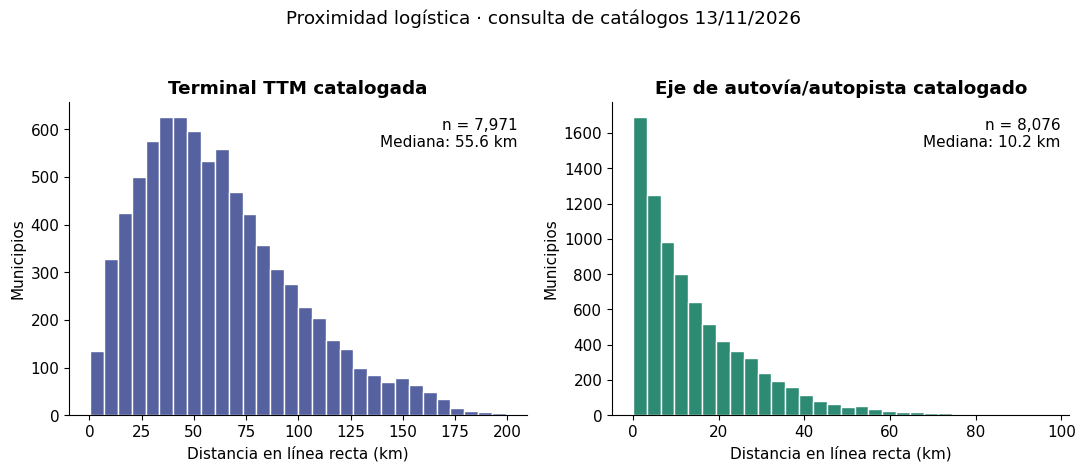

No se incluyen municipios sin destino catalogado en su componente terrestre. La ausencia no se convierte en cero. Las colas de las distribuciones indican lejanía al catálogo utilizado, no un tiempo de transporte medido.

In [13]:
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
for ax, col, titulo, color in zip(axes,
    ['dist_recta_ttm_km','dist_recta_eje_autovia_km'],
    ['Terminal TTM catalogada','Eje de autovía/autopista catalogado'], ['#5662a0','#2d8b74']):
    serie = logistica[col].dropna()
    ax.hist(serie, bins=30, color=color, edgecolor='white')
    ax.set(title=titulo, xlabel='Distancia en línea recta (km)', ylabel='Municipios')
    ax.text(.98,.95,f'n = {len(serie):,}\nMediana: {serie.median():.1f} km',
            transform=ax.transAxes, ha='right', va='top')
fig.suptitle('Proximidad logística · consulta de catálogos 13/11/2026', y=1.04)
figura(fig,'03_proximidad_logistica.png')
display(Markdown('No se incluyen municipios sin destino catalogado en su componente terrestre. '
    'La ausencia no se convierte en cero. Las colas de las distribuciones indican lejanía al '
    'catálogo utilizado, no un tiempo de transporte medido.'))

## 7. Suelo industrial: incorporar y revisar los originales
Elena aporta `Peninsula_IslasBaleares_Ceuta_Melilla.gpkg` y `Canarias.gpkg`. Ambos contienen una capa de polígonos `MSI` y una tabla `valores`. Utilizamos la **geometría de MSI** para calcular la superficie. No interpretamos las columnas SIOSE de `valores` como metros cuadrados o porcentajes sin su diccionario específico.

Los campos `cpro`, `municipio` e `IGRP_codine` no se asumen equivalentes a nuestros códigos INE. La inspección muestra discrepancias y códigos candidatos fuera del maestro, por lo que **no unimos las tablas por esos campos**. Guardamos las candidatas para auditoría y asignamos superficie mediante intersección espacial con los 8.132 municipios de la aplicación.

Se comprueba el número de filas, el CRS, las geometrías vacías e inválidas y la integridad SHA-256. Las reparaciones de geometría se registran. Los componentes sin superficie que pueda producir la reparación se descartan explícitamente: no contribuyen a hectáreas.

In [14]:
datos_industriales = []
inspeccion_industrial = []
for nombre in ['Peninsula_IslasBaleares_Ceuta_Melilla.gpkg', 'Canarias.gpkg']:
    ruta = RAW / 'suelo_industrial' / nombre
    original = gpd.read_file(ruta, layer='MSI', fid_as_index=True)
    assert original.crs is not None and not original.empty
    assert original.index.is_unique
    assert not original.geometry.isna().any() and not original.geometry.is_empty.any()
    datos = original.copy()
    datos['archivo_origen'] = nombre
    datos['fid_origen'] = original.index.astype(str)
    datos['id_poligono_fuente'] = nombre + '::' + datos.fid_origen
    datos['codigo_candidato_cpro_municipio'] = (
        datos.cpro.astype('Int64').astype(str).str.zfill(2) +
        datos.municipio.astype('Int64').astype(str).str.zfill(3))
    datos['codigo_candidato_igrp'] = datos.IGRP_codine.astype('string').str[:5]
    datos['geometria_invalida_original'] = ~datos.geometry.is_valid
    datos['geometry'] = shapely.make_valid(datos.geometry.values)
    # make_valid puede devolver GeometryCollection: solo conservamos sus polígonos.
    for idx in datos.index[datos.geometry.geom_type.eq('GeometryCollection')]:
        partes = shapely.get_parts(datos.at[idx,'geometry'])
        partes_area = [g for g in partes if g.geom_type in ('Polygon','MultiPolygon')]
        datos.at[idx,'geometry'] = shapely.union_all(partes_area)
    datos = datos.to_crs(6933)
    datos['geometria_reparada_tras_proyeccion'] = ~datos.geometry.is_valid
    datos['geometry'] = shapely.make_valid(datos.geometry.values)
    assert datos.geometry.is_valid.all() and datos.area.gt(0).all()
    inspeccion_industrial.append({'archivo':nombre,'filas':len(datos),
        'crs_original':str(original.crs),
        'geometrias_reparadas':int(datos.geometria_invalida_original.sum()),
        'reparadas_tras_proyeccion':int(datos.geometria_reparada_tras_proyeccion.sum()),
        'candidatos_cpro_municipio_fuera_maestro':int((~datos.codigo_candidato_cpro_municipio.isin(geo.cod_ine)).sum()),
        'area_validada_ha':float(datos.area.sum()/10000)})
    columnas = ['id_poligono_fuente','archivo_origen','fid_origen','codigo_candidato_cpro_municipio',
        'codigo_candidato_igrp','geometria_invalida_original','geometria_reparada_tras_proyeccion','geometry']
    datos_industriales.append(datos[columnas])
industria = gpd.GeoDataFrame(pd.concat(datos_industriales,ignore_index=True), crs=6933)
assert industria.id_poligono_fuente.is_unique and len(industria)==11968
csv(pd.DataFrame(inspeccion_industrial),'inspeccion_suelo_industrial.csv',QA)
csv(industria.drop(columns='geometry'),'referencias_poligonos_industriales.csv',QA)
display(pd.DataFrame(inspeccion_industrial).round(2))

,archivo,filas,crs_original,geometrias_reparadas,reparadas_tras_proyeccion,candidatos_cpro_municipio_fuera_maestro,area_validada_ha
0,Peninsula_IslasBaleares_Ceuta_Melilla.gpkg,11789,EPSG:4258,39,22,1391,217673.78
1,Canarias.gpkg,179,EPSG:4080,0,0,3,3124.22


### 7.1. Asignar superficie y eliminar solapes
Se intersecta la cartografía industrial detallada con los límites municipales GISCO 2024 usados en la aplicación. Después se hace la unión de las piezas dentro de cada municipio: las áreas superpuestas se cuentan **una sola vez**. Conservamos las áreas brutas, unidas y el exceso por solape para auditar el resultado.

La frontera GISCO es generalizada y de otra fecha. Parte de la superficie industrial costera o limítrofe puede quedar fuera del maestro: se registra por polígono y municipio, sin repartirla ni forzar una asignación. Las cifras son aproximaciones territoriales; no sirven para tramitar una parcela concreta.

Si el municipio no contiene ningún polígono del catálogo, el valor es **0 cartografiado**, con estado `sin_poligonos_en_catalogo`. Esto no demuestra ausencia física de industrias ni falta de suelo libre. El producto identifica áreas principales, no cada nave aislada. Ambos matices deben mostrarse en la aplicación.

In [15]:
piezas_industriales = gpd.overlay(industria, geo_area[['cod_ine','geometry']],
    how='intersection', keep_geom_type=True, make_valid=True)
piezas_industriales['area_bruta_m2'] = piezas_industriales.area
piezas_industriales = piezas_industriales[piezas_industriales.area_bruta_m2.gt(0)].copy()
csv(piezas_industriales.drop(columns='geometry'),'suelo_intersecciones.csv')
# Unión geométrica por municipio, antes de sumar áreas.
uniones = piezas_industriales[['cod_ine','geometry']].dissolve(by='cod_ine')
superficie_unida = uniones.area.rename('suelo_industrial_m2')
superficie_bruta = piezas_industriales.groupby('cod_ine').area_bruta_m2.sum().rename('superficie_bruta_m2')
recuento = piezas_industriales.groupby('cod_ine').id_poligono_fuente.nunique().rename('poligonos_fuente_intersectados')
suelo = geo[['cod_ine']].merge(pd.concat([superficie_unida,superficie_bruta,recuento],axis=1),
    on='cod_ine',how='left',validate='one_to_one')
suelo[['suelo_industrial_m2','superficie_bruta_m2','poligonos_fuente_intersectados']] = suelo[
    ['suelo_industrial_m2','superficie_bruta_m2','poligonos_fuente_intersectados']].fillna(0)
suelo['suelo_industrial_cartografiado_ha'] = suelo.suelo_industrial_m2/10000
suelo['suelo_industrial_cartografiado_pct'] = 100*suelo.suelo_industrial_m2/suelo.cod_ine.map(area_municipal)
suelo['solape_eliminado_m2'] = (suelo.superficie_bruta_m2-suelo.suelo_industrial_m2).clip(lower=0)
suelo['estado_suelo'] = np.where(suelo.suelo_industrial_m2.gt(0),'aproximado','sin_poligonos_en_catalogo')
assert suelo.suelo_industrial_cartografiado_pct.between(0,100.00001).all()
assert suelo.suelo_industrial_cartografiado_ha.ge(0).all()
capturada = piezas_industriales.groupby('id_poligono_fuente').area_bruta_m2.sum()
auditoria_poligonos = industria.drop(columns='geometry').copy()
auditoria_poligonos['area_original_validada_m2'] = industria.area
auditoria_poligonos['area_capturada_bruta_m2'] = auditoria_poligonos.id_poligono_fuente.map(capturada).fillna(0)
auditoria_poligonos['area_fuera_limites_m2'] = (auditoria_poligonos.area_original_validada_m2-
    auditoria_poligonos.area_capturada_bruta_m2).clip(lower=0)
csv(auditoria_poligonos,'auditoria_area_industrial.csv',QA)
csv(suelo,'suelo_industrial_municipal.csv')
balance_suelo = {
    'poligonos_originales':len(industria),'geometrias_reparadas':int(industria.geometria_invalida_original.sum()),
    'area_original_validada_ha':float(industria.area.sum()/10000),
    'area_intersectada_bruta_ha':float(piezas_industriales.area_bruta_m2.sum()/10000),
    'area_municipal_unida_ha':float(suelo.suelo_industrial_m2.sum()/10000),
    'solape_eliminado_ha':float(suelo.solape_eliminado_m2.sum()/10000),
    'area_fuera_limites_ha':float(auditoria_poligonos.area_fuera_limites_m2.sum()/10000),
    'municipios_con_poligonos':int(suelo.suelo_industrial_m2.gt(0).sum()),
    'municipios_sin_poligonos_catalogados':int(suelo.suelo_industrial_m2.eq(0).sum())}
(QA/'balance_suelo_industrial.json').write_text(json.dumps(balance_suelo,ensure_ascii=False,indent=2))
display(pd.DataFrame([balance_suelo]).T.rename(columns={0:'resultado'}).round(2))

,resultado
poligonos_originales,11968.00
geometrias_reparadas,39.00
area_original_validada_ha,220798.00
area_intersectada_bruta_ha,219257.96
area_municipal_unida_ha,219257.86
solape_eliminado_ha,0.09
area_fuera_limites_ha,1540.05
municipios_con_poligonos,3699.00
municipios_sin_poligonos_catalogados,4433.00


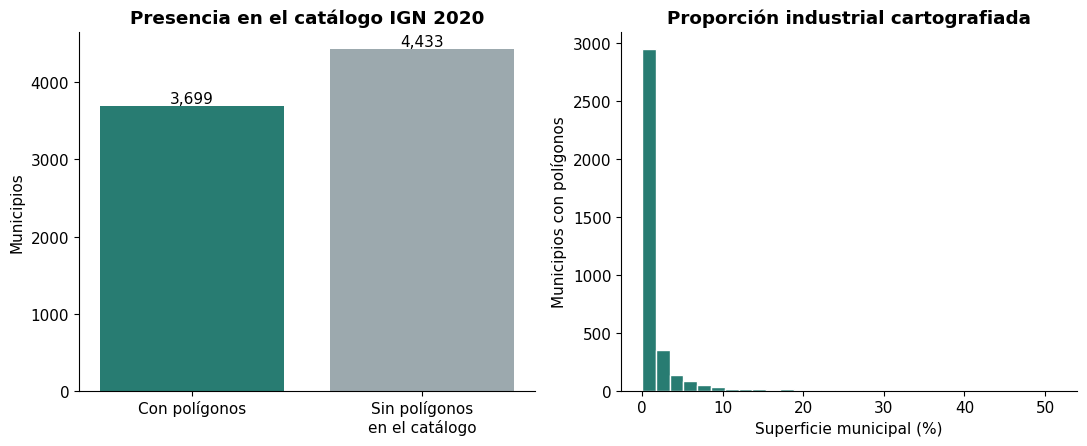

**3,699 municipios** intersectan al menos un polígono y **4,433** no contienen polígonos de este catálogo. Cero cartografiado no significa ausencia de industria ni suelo disponible. En los municipios con polígonos, la mediana es **0.33%** de su superficie.

In [16]:
fig, axes = plt.subplots(1,2,figsize=(11,4.6))
cantidades = [int(suelo.suelo_industrial_m2.gt(0).sum()),int(suelo.suelo_industrial_m2.eq(0).sum())]
axes[0].bar(['Con polígonos','Sin polígonos\nen el catálogo'],cantidades,color=['#287c72','#9ca9ae'])
for i,v in enumerate(cantidades):axes[0].text(i,v+35,f'{v:,}',ha='center')
axes[0].set(title='Presencia en el catálogo IGN 2020',ylabel='Municipios')
positivos = suelo.loc[suelo.suelo_industrial_m2.gt(0),'suelo_industrial_cartografiado_pct']
axes[1].hist(positivos,bins=30,color='#287c72',edgecolor='white')
axes[1].set(title='Proporción industrial cartografiada',xlabel='Superficie municipal (%)',ylabel='Municipios con polígonos')
figura(fig,'05_suelo_industrial.png')
display(Markdown(f'**{cantidades[0]:,} municipios** intersectan al menos un polígono y '
    f'**{cantidades[1]:,}** no contienen polígonos de este catálogo. '
    'Cero cartografiado no significa ausencia de industria ni suelo disponible. '
    f'En los municipios con polígonos, la mediana es **{positivos.median():.2f}%** de su superficie.'))

### 7.2. Qué sigue sin verificar para una actividad concreta
El archivo de suelo industrial ya está incorporado. Siguen faltando disponibilidad real de parcelas, caudal industrial contratable, acceso/ruta a autovía y capacidad/servicio operativo de las terminales cuando sean requisitos de la actividad. No se sustituyen por superficie cartografiada, estrés hídrico ni distancia al eje.

In [17]:
pendientes = pd.DataFrame([
    ['suelo_industrial_disponible_ha','sin_fuente_verificada',
     'Inventario municipal/operador con disponibilidad y fecha; MSI no certifica vacantes'],
    ['caudal_industrial_disponible_m3_dia','sin_fuente_verificada',
     'Operador abastecimiento/concesiones; estrés hídrico no lo certifica'],
    ['distancia_ruta_acceso_autovia_km','sin_fuente_verificada',
     'Enlaces de entrada y grafo de rutas; el eje no es acceso'],
    ['capacidad_terminal_para_actividad','requiere_validacion_local',
     'Confirmar estado operativo, capacidad y servicios para la actividad']
], columns=['variable','estado','necesario_para_resolver'])
csv(pendientes,'requisitos_pendientes.csv')
display(pendientes)

,variable,estado,necesario_para_resolver
0,suelo_industrial_disponible_ha,sin_fuente_verificada,Inventario municipal/operador con disponibilid...
1,caudal_industrial_disponible_m3_dia,sin_fuente_verificada,Operador abastecimiento/concesiones; estrés hí...
2,distancia_ruta_acceso_autovia_km,sin_fuente_verificada,Enlaces de entrada y grafo de rutas; el eje no...
3,capacidad_terminal_para_actividad,requiere_validacion_local,"Confirmar estado operativo, capacidad y servic..."


## 8. Integrar con v0.1 sin perder los estados
Conservamos los 16 indicadores anteriores y añadimos 9 indicadores con valores, incluidos los dos de suelo industrial. Exportamos municipios, diccionario, valores largos y tabla ancha. El suelo cartografiado sin polígonos tiene valor 0 y estado `sin_poligonos_en_catalogo`; no significa cero suelo libre ni ausencia física de industria.

`aproximado` identifica un cálculo territorial, no una medición municipal directa. Los estados `sin_cobertura_suficiente` y `sin_destino_catalogado_en_tierra` conservan nulos. Las coberturas son controles de calidad, no criterios para puntuar el atractivo.

In [18]:
dic_base = pd.read_csv(BASE/'indicadores.csv').fillna('')
val_base = pd.read_csv(BASE/'valores.csv', dtype={'cod_ine':str}).fillna({'fuentes_adicionales':''})
ampliacion = geo[['cod_ine']].merge(solar,on='cod_ine',validate='one_to_one').merge(
    hidrica,on='cod_ine',validate='one_to_one').merge(logistica,on='cod_ine',validate='one_to_one').merge(
    suelo[['cod_ine','suelo_industrial_cartografiado_ha','suelo_industrial_cartografiado_pct','estado_suelo']],
    on='cod_ine',validate='one_to_one')
def indicador(id_, nombre, bloque, tipo, unidad, sentido, fuente_id, fecha, nivel, metodo, naturaleza, limitacion):
    fuente = next(f for f in fuentes['fuentes'] if f['id']==fuente_id)
    return dict(id_indicador=id_,nombre=nombre,bloque=bloque,tipo=tipo,unidad=unidad,sentido=sentido,
        fuente_id=fuente_id,fuente=fuente['organismo'],url=fuente['url'],fecha_dato=fecha,
        nivel_origen=nivel,metodo=metodo,naturaleza=naturaleza,limitaciones=limitacion)
altas = [
 indicador('irradiacion_ghi_kwh_m2_anio','Recurso solar GHI medio','recurso_solar','atractivo','kWh/m2/anio','mayor_mejor','pvgis53','2005-2023','rejilla_0.05_grados','Intersección de celdas y media por área válida; cobertura >=95%','modelizado_y_agregado','No es rendimiento de planta ni medición municipal; rejilla SARAH3'),
 indicador('estres_hidrico_pct','Estrés hídrico medio territorial','agua','riesgo','%','menor_mejor','aqueduct4','baseline_objetivo_2019_publicada_2023','subcuenca','Media de bws_raw por área válida x100; cobertura >=95%','modelizado_y_agregado','No certifica abastecimiento ni estado mensual; puede superar100%'),
 indicador('agotamiento_hidrico_pct','Agotamiento hídrico medio territorial','agua','riesgo','%','menor_mejor','aqueduct4','baseline_objetivo_2019_publicada_2023','subcuenca','Media de bwd_raw por área válida x100; cobertura >=95%','modelizado_y_agregado','Consumo neto sobre disponibilidad; no caudal industrial'),
 indicador('superficie_estres_ge40_pct','Área válida en subcuencas con estrés >=40%','agua','riesgo','%','menor_mejor','aqueduct4','baseline_objetivo_2019_publicada_2023','subcuenca','Área con bws_raw>=0.4 / área con bws_raw válido x100; cobertura>=95%','modelizado_y_agregado','No es porcentaje de población afectada; umbral descriptivo'),
 indicador('dist_recta_ttm_km','Distancia recta a TTM catalogada','logistica','atractivo','km','menor_mejor','adif','consulta_2026-11-13','punto_infraestructura','Mínimo geodésico WGS84 dentro del mismo componente terrestre >=10km2','calculado','Punto interior municipal; no ruta, capacidad ni operatividad verificada'),
 indicador('dist_recta_ttm_intermodal_km','Distancia recta a TTM intermodal catalogada','logistica','atractivo','km','menor_mejor','adif','consulta_2026-11-13','punto_infraestructura','Igual que TTM; además MERCANCIAS_INTERMODAL=Sí','calculado','No confirma servicio o capacidad disponible'),
 indicador('dist_recta_eje_autovia_km','Distancia recta a eje autovía/autopista','logistica','atractivo','km','menor_mejor','hermes','consulta_2026-11-13','eje_infraestructura','Mínimo geométrico UTM local por componente terrestre; tipos Autopista*','calculado','Eje no equivale a enlace; cobertura del catálogo no garantiza exhaustividad'),
 indicador('suelo_industrial_cartografiado_ha','Superficie industrial cartografiada','suelo_industrial','atractivo','ha','depende_actividad','cnig_industrial','2020','poligono_industrial','Intersección MSI con municipios GISCO y unión geométrica por municipio; m2/10000','calculado','Áreas principales cartografiadas, no suelo libre; cero solo ausencia en el catálogo; fronteras generalizadas'),
 indicador('suelo_industrial_cartografiado_pct','Proporción industrial cartografiada','suelo_industrial','contexto','%','depende_actividad','cnig_industrial','2020','poligono_industrial','Área industrial unida / área de la misma geometría municipal x100','calculado','No es porcentaje de suelo libre ni de suelo legalmente urbanizable')]
dic_nuevo = pd.DataFrame(altas)
diccionario = pd.concat([dic_base, dic_nuevo],ignore_index=True)
assert diccionario.id_indicador.is_unique
filas = []
for ficha in altas:
    id_ = ficha['id_indicador']
    valores = ampliacion[id_] if id_ in ampliacion else pd.Series(np.nan,index=ampliacion.index)
    estado = np.where(valores.notna(),'aproximado','sin_cobertura_suficiente')
    if ficha['bloque']=='logistica': estado = np.where(valores.notna(),'aproximado','sin_destino_catalogado_en_tierra')
    if ficha['bloque']=='suelo_industrial': estado = ampliacion.estado_suelo.to_numpy()
    datos = pd.DataFrame({'cod_ine':ampliacion.cod_ine,'valor':valores,'id_indicador':id_,
        'estado':estado,'nivel_origen':ficha['nivel_origen'],'fecha_dato':ficha['fecha_dato'],
        'fuente_id':ficha['fuente_id'],'naturaleza':ficha['naturaleza'], 'metodo':ficha['metodo'],
        'url_fuente':ficha['url'],'fuentes_adicionales':'GISCO LAU 2024; INE códigos 2026'})
    filas.append(datos)
valores_nuevos = pd.concat(filas, ignore_index=True)
valores = pd.concat([val_base,valores_nuevos],ignore_index=True)
ancha = municipios.copy()
for atributo, prefijo in [('valor',''),('estado','estado__'),('nivel_origen','nivel_origen__')]:
    pivot = valores.pivot(index='cod_ine',columns='id_indicador',values=atributo).add_prefix(prefijo)
    ancha = ancha.merge(pivot,on='cod_ine',how='left',validate='one_to_one')
controles = ampliacion[['cod_ine','solar_cobertura_pct','solar_celdas','estres_hidrico_cobertura_pct',
    'agotamiento_hidrico_cobertura_pct','agua_subcuencas','id_tierra','ttm_mas_cercana',
    'ttm_intermodal_mas_cercana','autovia_mas_cercana']]
ancha = ancha.merge(controles,on='cod_ine',validate='one_to_one')
assert len(ancha)==8132 and len(valores)==8132*len(diccionario)
assert not valores.duplicated(['cod_ine','id_indicador']).any()
csv(municipios,'municipios.csv');csv(diccionario,'indicadores.csv');csv(valores,'valores.csv')
csv(ancha,'dataset_municipal.csv');csv(controles,'calidad_y_referencias.csv')
display(dic_nuevo[['id_indicador','bloque','naturaleza']])

,id_indicador,bloque,naturaleza
0,irradiacion_ghi_kwh_m2_anio,recurso_solar,modelizado_y_agregado
1,estres_hidrico_pct,agua,modelizado_y_agregado
2,agotamiento_hidrico_pct,agua,modelizado_y_agregado
3,superficie_estres_ge40_pct,agua,modelizado_y_agregado
4,dist_recta_ttm_km,logistica,calculado
5,dist_recta_ttm_intermodal_km,logistica,calculado
6,dist_recta_eje_autovia_km,logistica,calculado
7,suelo_industrial_cartografiado_ha,suelo_industrial,calculado
8,suelo_industrial_cartografiado_pct,suelo_industrial,calculado


## 9. Comprobar cobertura y el contrato para la aplicación
La cobertura indica dónde existe una estimación utilizable con el método elegido; no mide precisión. Incluimos comprobaciones independientes de cardinalidad, códigos, rangos, jerarquía de distancias y conservación de valores v0.1.

Para cualquier requisito eliminatorio que dependa de caudal disponible, suelo vacante o acceso real, la respuesta sigue siendo **desconocido** hasta contar con la fuente adecuada. La interfaz debe mostrar esa incertidumbre y pedir comprobación local; no puede recomendar como viable una papelera solo porque el contexto hídrico resulte favorable.

,id_indicador,municipios,con_dato,sin_dato,cobertura_pct
0,irradiacion_ghi_kwh_m2_anio,8132,8132,0,100.00
1,estres_hidrico_pct,8132,8108,24,99.70
2,agotamiento_hidrico_pct,8132,8108,24,99.70
3,superficie_estres_ge40_pct,8132,8108,24,99.70
4,dist_recta_ttm_km,8132,7971,161,98.02
5,dist_recta_ttm_intermodal_km,8132,7971,161,98.02
6,dist_recta_eje_autovia_km,8132,8076,56,99.31
7,suelo_industrial_cartografiado_ha,8132,8132,0,100.00
8,suelo_industrial_cartografiado_pct,8132,8132,0,100.00


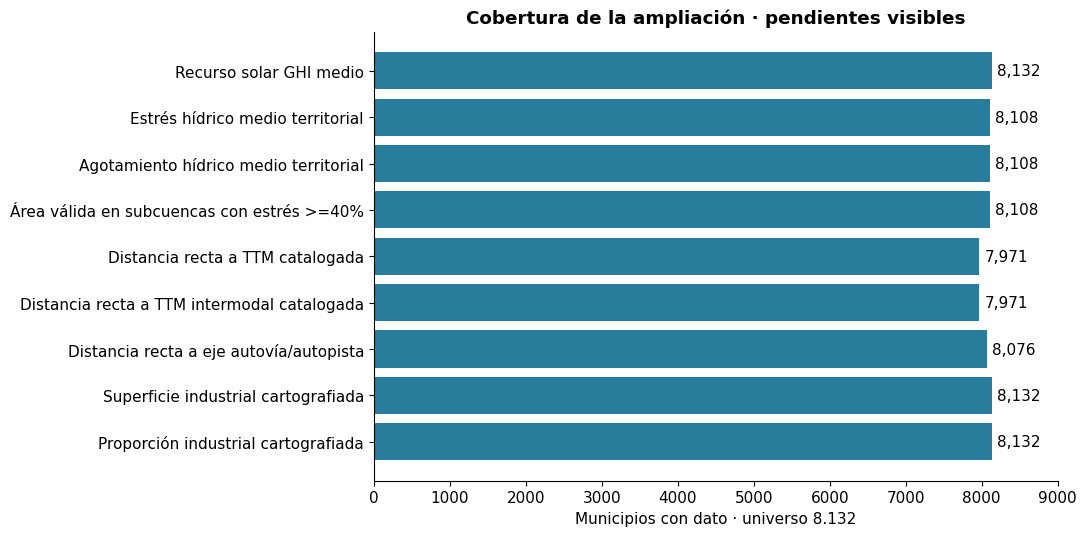

Controles superados. Salidas: data\processed\sitewise_v02


In [20]:
cobertura = (valores_nuevos.groupby('id_indicador',sort=False)
    .agg(municipios=('cod_ine','size'),con_dato=('valor','count')).reset_index())
cobertura['sin_dato'] = cobertura.municipios-cobertura.con_dato
cobertura['cobertura_pct'] = 100*cobertura.con_dato/cobertura.municipios
csv(cobertura,'cobertura_ampliacion.csv',QA)
antes = val_base.set_index(['cod_ine','id_indicador'])['valor'].sort_index()
despues = valores[valores.id_indicador.isin(dic_base.id_indicador)].set_index(['cod_ine','id_indicador'])['valor'].sort_index()
pd.testing.assert_series_equal(antes,despues)
assert valores_nuevos.loc[valores_nuevos.estado.eq('sin_poligonos_en_catalogo'),'valor'].eq(0).all()
assert not valores_nuevos.estado.eq('pendiente_fuente').any()
assert ancha.cod_ine.is_unique and ancha.cod_ine.str.fullmatch(r'\d{5}').all()
display(cobertura.round(2))
fig, ax = plt.subplots(figsize=(11,5.5))
etiquetas = dic_nuevo.set_index('id_indicador').loc[cobertura.id_indicador,'nombre'].to_list()
ax.barh(etiquetas[::-1],cobertura.con_dato.iloc[::-1],color='#277d9b')
ax.set(xlim=(0,9000),xlabel='Municipios con dato · universo 8.132',
       title='Cobertura de la ampliación · pendientes visibles')
for i,v in enumerate(cobertura.con_dato.iloc[::-1]): ax.text(v+65,i,f'{v:,}',va='center')
figura(fig,'04_cobertura_ampliacion.png')
validacion = {'municipios':len(ancha),'indicadores_totales':len(diccionario),
    'indicadores_nuevos_con_valores':int(cobertura.con_dato.gt(0).sum()),
    'indicadores_pendientes_fuente':int(cobertura.con_dato.eq(0).sum()),
    'valores_largos':len(valores),'duplicados_clave':0,'conservacion_v01':'correcta',
    'python':platform.python_version(),'pandas':pd.__version__,'geopandas':gpd.__version__,
    'rasterio':rasterio.__version__,'shapely':shapely.__version__,
    'ejecucion':'cuaderno completo, copias incluidas; reconstrucción opcional no ejecutada en esta pasada'}
(QA/'validacion.json').write_text(json.dumps(validacion,ensure_ascii=False,indent=2),encoding='utf-8')
print('Controles superados. Salidas:', OUT.relative_to(ROOT))

## 10. Lectura de resultados y siguiente paso
La tabla ancha de `data/processed/sitewise_v02/dataset_municipal.csv` es la entrada de pruebas del backend. `indicadores.csv` documenta cada campo y `valores.csv` conserva estado, fuente y fecha. Los CSV son UTF-8 con BOM: leer `cod_ine` como texto. Los gráficos están guardados en el cuaderno y en `docs/data/sitewise_v02/`.

Se han incorporado los dos archivos de suelo industrial. Hay datos cartográficos de las cuatro familias de esta ampliación, con sus límites explícitos. **Todavía no se certifica viabilidad para cada actividad:** el suelo libre y el caudal contratable, y en su caso rutas de acceso y capacidad ferroviaria, requieren sus fuentes concretas. Los requisitos sin verificar permanecen en `requisitos_pendientes.csv`.

No se calculan pesos inventados, filtros eliminatorios sin validar ni recomendaciones de inversión. No se añade exposición inundable. La red ferroviaria de líneas no es necesaria para repetir las distancias a TTM del catálogo; sí sería otra fuente para analizar trazados, conectividad o rutas, que no se han calculado aquí.

Los originales GeoPackage son grandes y se conservan en `data/raw/`, excluido por el `.gitignore` existente. No deben forzarse al repositorio. El notebook se puede subir a Git con sus gráficos; la entrega de datos necesita el mecanismo de distribución que acuerde el equipo.